In [1]:
import sys
sys.path.append("..") # lets the notebook import from src/ later
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
train = pd.read_csv("../data/raw/train.csv")
test = pd.read_csv("../data/raw/test.csv")
print(train.shape, test.shape) # (1460, 81) (1459, 80)
train.head()

(1460, 81) (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
print(set(train.columns) - set(test.columns)) # {'SalePrice'}: the answer exists only in train
features = [c for c in train.columns if c not in ("Id", "SalePrice")]
print(len(features), "features") # 79

{'SalePrice'}
79 features


In [4]:
raw = pd.read_csv("../data/raw/train.csv", keep_default_na=False) # read every "NA" as plain text
print((raw["Alley"] == "NA").sum(), "houses literally say 'NA' for Alley")
print(train["Alley"].isna().sum(), "missing values in Alley after the normal read")

1369 houses literally say 'NA' for Alley
1369 missing values in Alley after the normal read


In [5]:
train[features].dtypes.value_counts() # numbers vs text columns

str        43
int64      33
float64     3
Name: count, dtype: int64

In [6]:
missing = train[features].isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "percent": (missing / len(train) * 100).round(1)})

,missing,percent
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


skew: 1.88  kurtosis: 6.54


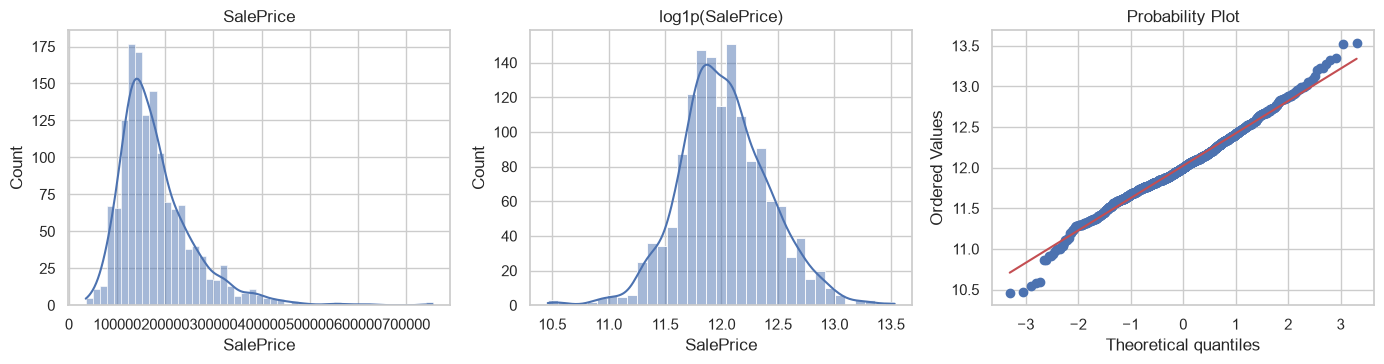

skew after log: 0.12


In [7]:
print("skew:", round(train["SalePrice"].skew(), 2), " kurtosis:", round(train["SalePrice"].kurt(), 2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(train["SalePrice"], kde=True, ax=axes[0]); axes[0].set_title("SalePrice")
sns.histplot(np.log1p(train["SalePrice"]), kde=True, ax=axes[1]); axes[1].set_title("log1p(SalePrice)")
stats.probplot(np.log1p(train["SalePrice"]), plot=axes[2])
plt.tight_layout(); plt.show()
print("skew after log:", round(np.log1p(train["SalePrice"]).skew(), 2))

OverallQual     0.79
GrLivArea       0.71
GarageCars      0.64
GarageArea      0.62
TotalBsmtSF     0.61
1stFlrSF        0.61
FullBath        0.56
TotRmsAbvGrd    0.53
YearBuilt       0.52
YearRemodAdd    0.51
Name: SalePrice, dtype: float64
YrSold          -0.03
OverallCond     -0.08
MSSubClass      -0.08
EnclosedPorch   -0.13
KitchenAbvGr    -0.14
Name: SalePrice, dtype: float64


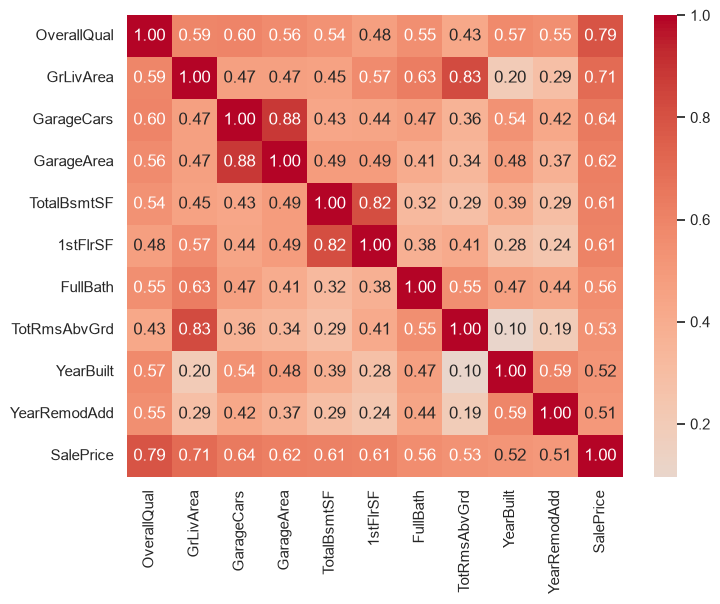

In [8]:
corr = train.corr(numeric_only=True)["SalePrice"].drop("SalePrice").sort_values(ascending=False)
print(corr.head(10).round(2))
print(corr.tail(5).round(2))
top = corr.abs().sort_values(ascending=False).head(10).index.tolist() + ["SalePrice"]
plt.figure(figsize=(8, 6))
sns.heatmap(train[top].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

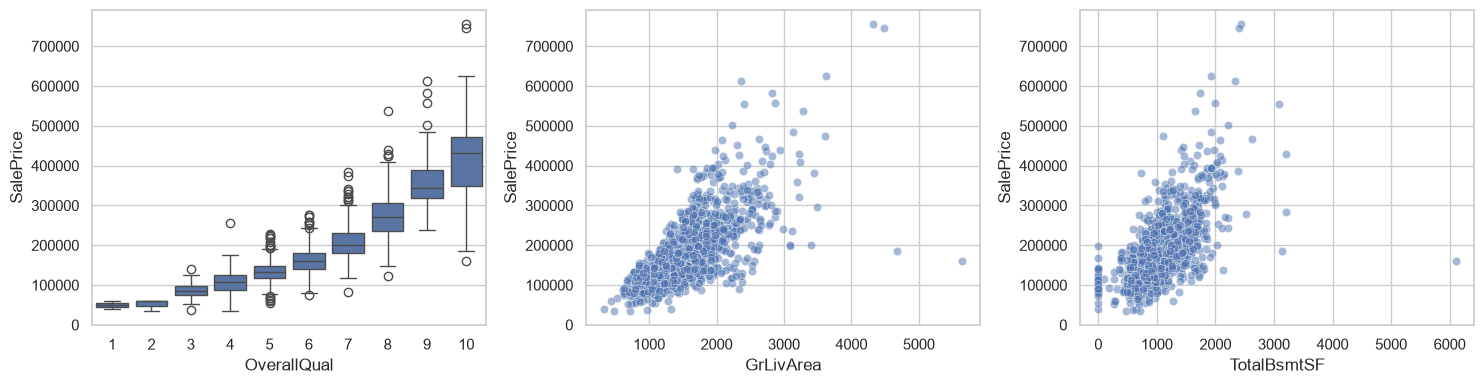

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=train, x="OverallQual", y="SalePrice", ax=axes[0])
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", alpha=.5, ax=axes[1])
sns.scatterplot(data=train, x="TotalBsmtSF", y="SalePrice", alpha=.5, ax=axes[2])
plt.tight_layout(); plt.show()

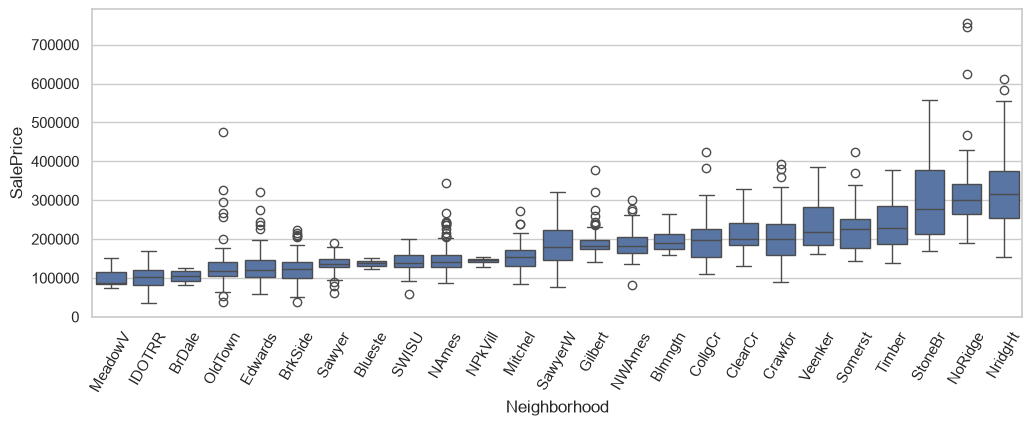

In [10]:
order = train.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(12, 4))
sns.boxplot(data=train, x="Neighborhood", y="SalePrice", order=order)
plt.xticks(rotation=60); plt.show()


In [11]:
train[train["GrLivArea"] > 4000][["Id", "GrLivArea", "SalePrice", "SaleCondition"]]

,Id,GrLivArea,SalePrice,SaleCondition
523,524,4676,184750,Partial
691,692,4316,755000,Normal
1182,1183,4476,745000,Abnorml
1298,1299,5642,160000,Partial


In [12]:
train.groupby("YrSold")["SalePrice"].agg(["median", "count"])

,median,count
YrSold,,
2006,163995.0,314
2007,167000.0,329
2008,164000.0,304
2009,162000.0,338
2010,155000.0,175
